# CS05: Segment stability (Online Retail II)

Thresholds are fixed in `core.py` before the bootstrap runs:
median bootstrap ARI ≥ 0.80 and cross-window ARI ≥ 0.60 count as stable.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from stabseg.core import (
    K,
    N_BOOT,
    SNAPSHOT_EARLY,
    SNAPSHOT_MAIN,
    STABLE_BOOTSTRAP_MEDIAN_ARI,
    STABLE_CROSS_WINDOW_ARI,
    bootstrap_ari,
    centroid_drift,
    cross_window_ari,
    data_path,
    fit_kmeans,
    fit_scaler,
    load_retail,
    rfm_features,
    stability_verdict,
    transform,
)

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
tx = load_retail()
print("data:", data_path())
feats_main = rfm_features(tx, SNAPSHOT_MAIN)
feats_early = rfm_features(tx, SNAPSHOT_EARLY)
print("customers at main snapshot:", len(feats_main))
print("customers at early snapshot:", len(feats_early))
print("shared customers:", len(feats_main.index.intersection(feats_early.index)))

data: /home/patotricks15/.local/share/clv-data/online-retail-ii/online_retail_II.csv


customers at main snapshot: 4933
customers at early snapshot: 3321
shared customers: 3321


In [3]:
scaler = fit_scaler(feats_main)
X = transform(feats_main, scaler)
model = fit_kmeans(X, K)
ref_labels = model.labels_
print("segment sizes:", np.bincount(ref_labels).tolist())
print("smallest share:", round(np.bincount(ref_labels).min() / len(ref_labels), 3))

segment sizes: [2091, 1122, 1720]
smallest share: 0.227


In [4]:
boot = bootstrap_ari(X, ref_labels, k=K, n_boot=N_BOOT)
boot_summary = pd.Series(
    {
        "n_boot": N_BOOT,
        "median_ari": np.median(boot),
        "mean_ari": boot.mean(),
        "p05_ari": np.percentile(boot, 5),
        "min_ari": boot.min(),
    }
)
boot_summary.round(3)

n_boot        50.000
median_ari     0.944
mean_ari       0.927
p05_ari        0.827
min_ari        0.799
dtype: float64

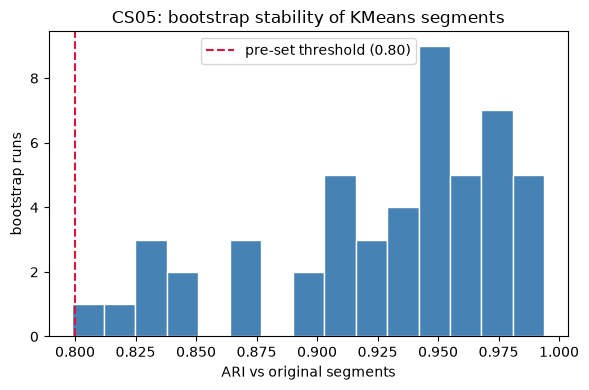

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(boot, bins=15, color="steelblue", edgecolor="white")
ax.axvline(STABLE_BOOTSTRAP_MEDIAN_ARI, color="crimson", linestyle="--", label="pre-set threshold (0.80)")
ax.set_xlabel("ARI vs original segments")
ax.set_ylabel("bootstrap runs")
ax.set_title("CS05: bootstrap stability of KMeans segments")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "cs05_bootstrap_ari.png", dpi=150)
plt.show()

In [6]:
cw_ari, shared_labels = cross_window_ari(feats_early, feats_main, k=K)
print("cross-window ARI (model A vs model B on shared customers):", round(cw_ari, 3))
print("shared customers used:", len(shared_labels))

cross-window ARI (model A vs model B on shared customers): 0.804
shared customers used: 3321


In [7]:
scaler_a = fit_scaler(feats_early)
model_a = fit_kmeans(transform(feats_early, scaler_a), K)
# Both windows use the early-window scaler, so centroids share one coordinate system.
model_b = fit_kmeans(transform(feats_main, scaler_a), K)
drift, matched = centroid_drift(model_a.cluster_centers_, model_b.cluster_centers_)
drift_table = pd.DataFrame(
    {"early_centroid": range(K), "matched_main_centroid": matched, "drift": drift}
)
drift_table.round(3)

,early_centroid,matched_main_centroid,drift
0,0,1,0.351
1,1,0,0.433
2,2,2,0.567


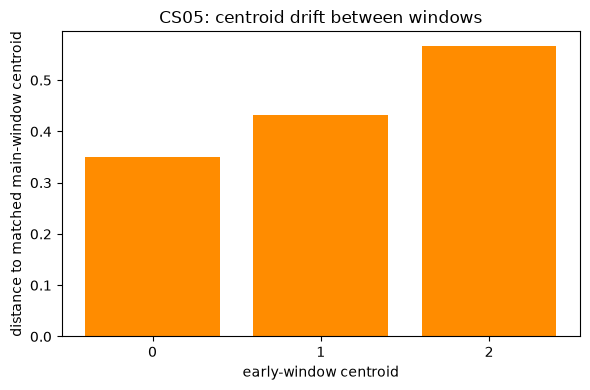

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(drift_table["early_centroid"].astype(str), drift_table["drift"], color="darkorange")
ax.set_xlabel("early-window centroid")
ax.set_ylabel("distance to matched main-window centroid")
ax.set_title("CS05: centroid drift between windows")
fig.tight_layout()
fig.savefig(FIG / "cs05_centroid_drift.png", dpi=150)
plt.show()

In [9]:
verdict_bootstrap = stability_verdict(np.median(boot), cw_ari)
print("bootstrap median ARI:", round(np.median(boot), 3), "threshold:", STABLE_BOOTSTRAP_MEDIAN_ARI)
print("cross-window ARI:", round(cw_ari, 3), "threshold:", STABLE_CROSS_WINDOW_ARI)
print("verdict:", verdict_bootstrap)

bootstrap median ARI: 0.944 threshold: 0.8
cross-window ARI: 0.804 threshold: 0.6
verdict: stable
